In [2]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error
import pandas as pd
from sklearn.model_selection import train_test_split

In [3]:
insurance_data=pd.read_csv("insurance.csv")
x=insurance_data.drop(columns=["charges"])
y=insurance_data["charges"]

x=pd.get_dummies(x, columns=["region"], drop_first=True, dtype=int)
x["sex"]=x["sex"].map({"female":1, "male":0})
x["smoker"]=x["smoker"].map({"yes":1, "no":0})
x.head()

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,0,0,1
1,18,0,33.770,1,0,0,1,0
2,28,0,33.000,3,0,0,1,0
3,33,0,22.705,0,0,1,0,0
4,32,0,28.880,0,0,1,0,0


mase values 0.001: 33596924.38828374
mase values 0.01: 33597001.223820455
mase values 1: 33605507.57554603
mase values 2: 33614211.30874087
mase values 5: 33639750.85985903
mase values 10: 33679511.30099594
mase values 20: 33766604.715291016
mase values 30: 33855740.161839
mase values 40: 33947018.40367207
mase values 50: 34042719.501167394
mase values 100: 34245283.94567649
mase values 300: 35171466.422103226


<Axes: >

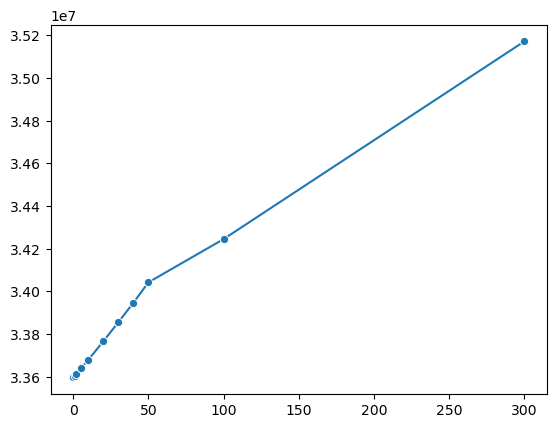

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42)
import seaborn as sns
alphas=[0.001, 0.01, 1,2,5,10,20, 30, 40, 50, 100, 300]
mses=[]
for a in alphas:
    lasso_model=Lasso(alpha=a)
    lasso_model.fit(X_train, y_train)
    y_pred=lasso_model.predict(X_test)
    mse=mean_squared_error(y_test, y_pred)
    X_train.head()
    print(f"mase values {a}:",mse)
    mses.append(mse)
sns.lineplot(x=alphas, y=mses, marker="o")

In [29]:
#Lasso CV ( Cross Validation)
from sklearn.linear_model import LassoCV
a=[0.001, 0.01, 1,2,5,10,20, 30, 40, 50, 100, 300]
lasso_cv_model=LassoCV(
    alphas=a,
    cv=5,
    max_iter=1000,
    random_state=42
)
lasso_cv_model.fit(X_train, y_train)
print(lasso_cv_model.alpha_)
y_pred=lasso_cv_model.predict(X_test)
mse=mean_squared_error(y_test, y_pred)
print(mse)

100.0
34245283.94567649
